**Author:** [@celine-am](https://github.com/celine-am)

# Repeatability

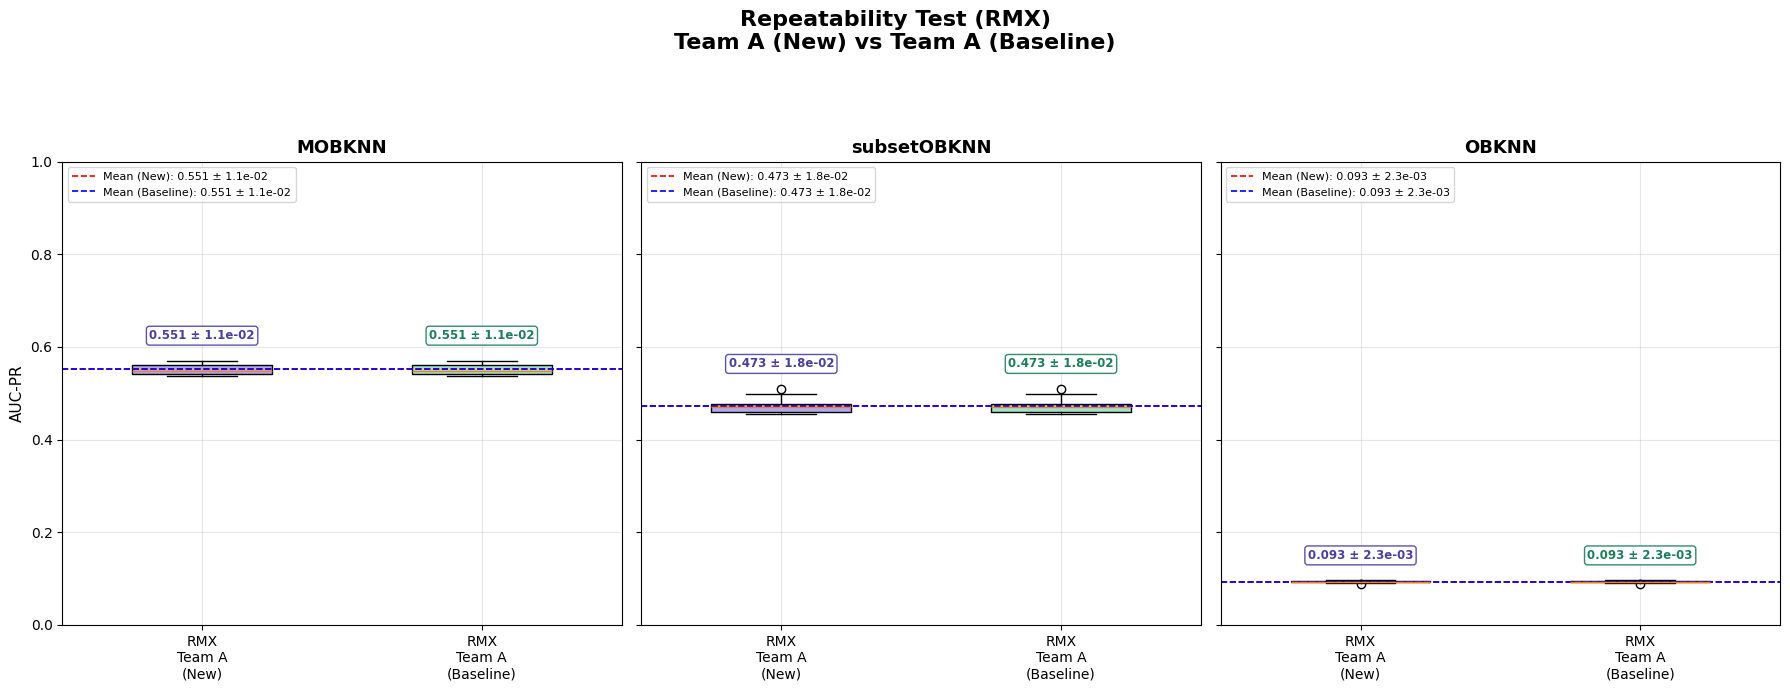

Method,RMX - Team A (New),RMX - Team A (Baseline)
MOBKNN,0.551 ± 1.1e-02,0.551 ± 1.1e-02
subsetOBKNN,0.473 ± 1.8e-02,0.473 ± 1.8e-02
OBKNN,0.093 ± 2.3e-03,0.093 ± 2.3e-03


\begin{table}[!htbp]
\centering
\caption{Repeatability Test (RMX): Mean AUC-PR $\pm$ standard deviation for Team A (New) vs Team A (Baseline). The highest value is highlighted in bold, and the second best is underlined.}
\label{tab:auc_pr_repeatability}
\footnotesize
\setlength{\tabcolsep}{8pt}
\begin{tabular}{lcc}
\toprule
\textbf{Method} & \textbf{RMX - Team A (New)} & \textbf{RMX - Team A (Baseline)} \\
\midrule
MOBKNN & \textbf{0.551} $\pm$ 1.1e-02 & \textbf{0.551} $\pm$ 1.1e-02 \\ \addlinespace
subsetOBKNN & \underline{0.473} $\pm$ 1.8e-02 & \underline{0.473} $\pm$ 1.8e-02 \\ \addlinespace
OBKNN & 0.093 $\pm$ 2.3e-03 & 0.093 $\pm$ 2.3e-03 \\
\bottomrule
\end{tabular}
\end{table}


In [29]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# Directories
# ==========================================================
BASE_DIR = Path.cwd() if (Path.cwd() / "Baseline (Team A)").exists() else Path(r"C:\Users\nicol\Plots + Data")
BASELINE_DIR = BASE_DIR / "Baseline (Team A)"
REPEATABILITY_DIR = BASE_DIR / "Repeatability (Team A)"
ROBUSTNESS_DIR = BASE_DIR / "Robustness (Team B)"

# ==========================================================
# Repeatability Test (RMX)
# Team A (New) vs Team A (Baseline)
# ==========================================================

datasets = {
    "MOBKNN": (
        pd.read_csv(REPEATABILITY_DIR / "summary_results_repetabiliy_RMX_MOBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_MOBKNN.csv")
    ),
    "subsetOBKNN": (
        pd.read_csv(REPEATABILITY_DIR / "summary_results_repetabiliy_RMX_subsetobknn.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_subsetobknn.csv")
    ),
    "OBKNN": (
        pd.read_csv(REPEATABILITY_DIR / "summary_results_repetabiliy_RMX_OBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_OBKNN.csv")
    )
}

# ==========================================================
# Figure : 1 ligne × 3 colonnes
# ==========================================================
fig, axes = plt.subplots(
    1,
    len(datasets),
    figsize=(18, 7),
    sharey=True
)

for i, (ax, (name, (df, baseline_df))) in enumerate(zip(axes, datasets.items())):

    bp = ax.boxplot(
        [df["raw_pr_auc"], baseline_df["raw_pr_auc"]],
        tick_labels=[
            "RMX\nTeam A\n(New)",
            "RMX\nTeam A\n(Baseline)"
        ],
        patch_artist=True,
        widths=0.5
    )

    # Colors
    bp["boxes"][0].set_facecolor("#AFA9EC")
    bp["boxes"][1].set_facecolor("#9FE1CB")

    # Style
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)

    # Shared y-axis
    if i == 0:
        ax.set_ylabel("AUC-PR", fontsize=11)

    ax.set_title(
        name,
        fontsize=13,
        fontweight="bold"
    )

    mean_new, std_new = df["raw_pr_auc"].mean(), df["raw_pr_auc"].std()
    mean_baseline, std_baseline = baseline_df["raw_pr_auc"].mean(), baseline_df["raw_pr_auc"].std()

    ax.axhline(
        mean_new,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean (New): {mean_new:.3f} ± {std_new:.1e}"
    )

    ax.axhline(
        mean_baseline,
        color="blue",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean (Baseline): {mean_baseline:.3f} ± {std_baseline:.1e}"
    )

    # Annotate value ± std directly above each boxplot
    for x_pos, series, m_val, s_val, color in [
        (1, df["raw_pr_auc"], mean_new, std_new, "#4A3F9F"),
        (2, baseline_df["raw_pr_auc"], mean_baseline, std_baseline, "#1E7E5A")
    ]:
        ax.text(
            x_pos,
            min(series.max() + 0.04, 0.94),
            f"{m_val:.3f} ± {s_val:.1e}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color=color,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9)
        )

    ax.legend(
        loc="upper left",
        fontsize=8,
        frameon=True
    )

plt.suptitle(
    "Repeatability Test (RMX)\nTeam A (New) vs Team A (Baseline)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.show()

# ==========================================================
# Publication Table (HTML + LaTeX) : Repeatability Test (RMX)
# ==========================================================
from IPython.display import display, HTML

def render_and_build_table(datasets_dict, col1_name, col2_name, caption, label):
    stats = {}
    for method, (df1, df2) in datasets_dict.items():
        s1, s2 = df1["raw_pr_auc"], df2["raw_pr_auc"]
        stats[method] = {
            "c1": (s1.mean(), s1.std()),
            "c2": (s2.mean(), s2.std())
        }
    ranks = {}
    for col_key in ["c1", "c2"]:
        ordered = sorted(stats.keys(), key=lambda m: stats[m][col_key][0], reverse=True)
        ranks[col_key] = {ordered[0]: 1, ordered[1]: 2}

    def fmt_latex(method, col_key):
        m_val, s_val = stats[method][col_key]
        m_str = f"{m_val:.3f}"
        if ranks[col_key].get(method) == 1:
            m_str = f"\\textbf{{{m_str}}}"
        elif ranks[col_key].get(method) == 2:
            m_str = f"\\underline{{{m_str}}}"
        return f"{m_str} $\\pm$ {s_val:.1e}"

    def fmt_html(method, col_key):
        m_val, s_val = stats[method][col_key]
        m_str = f"{m_val:.3f}"
        if ranks[col_key].get(method) == 1:
            m_str = f"<b>{m_str}</b>"
        elif ranks[col_key].get(method) == 2:
            m_str = f"<u>{m_str}</u>"
        return f"{m_str} &plusmn; {s_val:.1e}"

    methods = list(datasets_dict.keys())
    html_rows = "".join([
        f"<tr><td style='text-align:left;padding:6px 12px;'>{m}</td>"
        f"<td style='text-align:center;padding:6px 12px;'>{fmt_html(m, 'c1')}</td>"
        f"<td style='text-align:center;padding:6px 12px;'>{fmt_html(m, 'c2')}</td></tr>"
        for m in methods
    ])
    html_caption = caption.replace("$\\pm$", "&plusmn;")
    html_table = f"""
    <div style='margin:12px 0;font-family:serif;'>
      <p style='margin-bottom:6px;font-size:13px;'><b>Table ({label}):</b> {html_caption}</p>
      <table style='border-collapse:collapse;border-top:2px solid black;border-bottom:2px solid black;font-size:13px;'>
        <thead>
          <tr style='border-bottom:1px solid black;'>
            <th style='text-align:left;padding:6px 12px;'>Method</th>
            <th style='text-align:center;padding:6px 12px;'>{col1_name}</th>
            <th style='text-align:center;padding:6px 12px;'>{col2_name}</th>
          </tr>
        </thead>
        <tbody>{html_rows}</tbody>
      </table>
    </div>
    """
    display(HTML(html_table))

    lines = [
        "\\begin{table}[!htbp]",
        "\\centering",
        f"\\caption{{{caption}}}",
        f"\\label{{{label}}}",
        "\\footnotesize",
        "\\setlength{\\tabcolsep}{8pt}",
        "\\begin{tabular}{lcc}",
        "\\toprule",
        f"\\textbf{{Method}} & \\textbf{{{col1_name}}} & \\textbf{{{col2_name}}} \\\\",
        "\\midrule"
    ]
    for idx, method in enumerate(methods):
        end = " \\\\ \\addlinespace" if idx < len(methods) - 1 else " \\\\"
        lines.append(f"{method} & {fmt_latex(method, 'c1')} & {fmt_latex(method, 'c2')}{end}")
    lines += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
    return "\n".join(lines)

latex_repeatability = render_and_build_table(
    datasets,
    "RMX - Team A (New)",
    "RMX - Team A (Baseline)",
    "Repeatability Test (RMX): Mean AUC-PR $\\pm$ standard deviation for Team A (New) vs Team A (Baseline). The highest value is highlighted in bold, and the second best is underlined.",
    "tab:auc_pr_repeatability"
)
print(latex_repeatability)

# Reproducibility


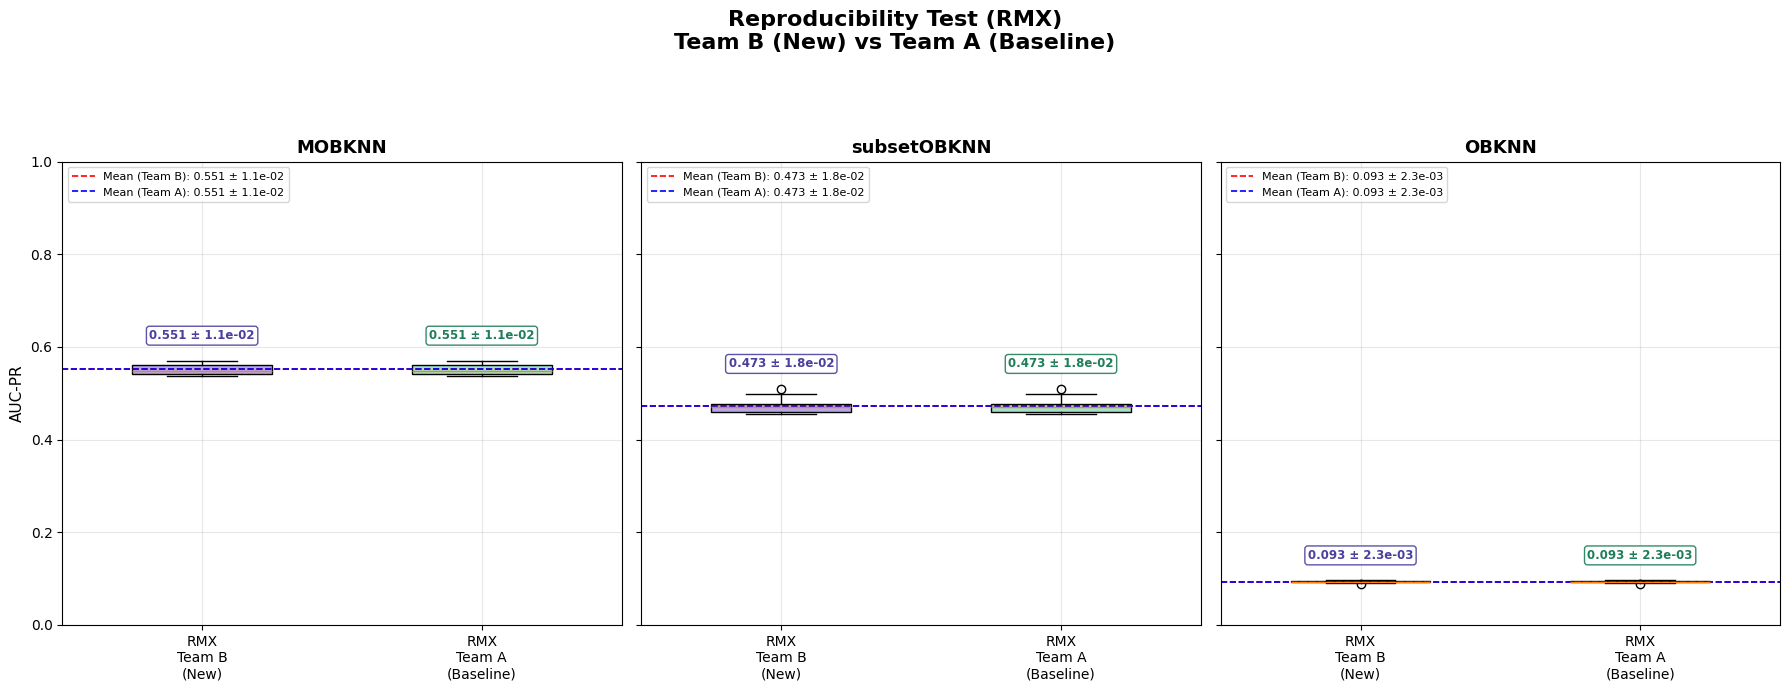

Method,RMX - Team B (New),RMX - Team A (Baseline)
MOBKNN,0.551 ± 1.1e-02,0.551 ± 1.1e-02
subsetOBKNN,0.473 ± 1.8e-02,0.473 ± 1.8e-02
OBKNN,0.093 ± 2.3e-03,0.093 ± 2.3e-03


\begin{table}[!htbp]
\centering
\caption{Reproducibility Test (RMX): Mean AUC-PR $\pm$ standard deviation for Team B (New) vs Team A (Baseline). The highest value is highlighted in bold, and the second best is underlined.}
\label{tab:auc_pr_reproducibility}
\footnotesize
\setlength{\tabcolsep}{8pt}
\begin{tabular}{lcc}
\toprule
\textbf{Method} & \textbf{RMX - Team B (New)} & \textbf{RMX - Team A (Baseline)} \\
\midrule
MOBKNN & \textbf{0.551} $\pm$ 1.1e-02 & \textbf{0.551} $\pm$ 1.1e-02 \\ \addlinespace
subsetOBKNN & \underline{0.473} $\pm$ 1.8e-02 & \underline{0.473} $\pm$ 1.8e-02 \\ \addlinespace
OBKNN & 0.093 $\pm$ 2.3e-03 & 0.093 $\pm$ 2.3e-03 \\
\bottomrule
\end{tabular}
\end{table}


In [30]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# Directories
# ==========================================================
BASE_DIR = Path.cwd() if (Path.cwd() / "Baseline (Team A)").exists() else Path(r"C:\Users\nicol\Plots + Data")
BASELINE_DIR = BASE_DIR / "Baseline (Team A)"
ROBUSTNESS_DIR = BASE_DIR / "Robustness (Team B)"

# ==========================================================
# Reproducibility Test (RMX)
# Team B (New) vs Team A (Baseline)
# ==========================================================

datasets = {
    "MOBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_MOBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_MOBKNN.csv")
    ),
    "subsetOBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_subsetOBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_subsetobknn.csv")
    ),
    "OBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_OBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_OBKNN.csv")
    )
}

# ==========================================================
# Figure : 1 ligne × 3 colonnes
# ==========================================================
fig, axes = plt.subplots(
    1,
    len(datasets),
    figsize=(18, 7),
    sharey=True
)

for i, (ax, (name, (df, baseline_df))) in enumerate(zip(axes, datasets.items())):

    bp = ax.boxplot(
        [df["raw_pr_auc"], baseline_df["raw_pr_auc"]],
        tick_labels=[
            "RMX\nTeam B\n(New)",
            "RMX\nTeam A\n(Baseline)"
        ],
        patch_artist=True,
        widths=0.5
    )

    # Colors
    bp["boxes"][0].set_facecolor("#AFA9EC")
    bp["boxes"][1].set_facecolor("#9FE1CB")

    # Style
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)

    # Shared y-axis
    if i == 0:
        ax.set_ylabel("AUC-PR", fontsize=11)

    ax.set_title(
        name,
        fontsize=13,
        fontweight="bold"
    )

    mean_new, std_new = df["raw_pr_auc"].mean(), df["raw_pr_auc"].std()
    mean_baseline, std_baseline = baseline_df["raw_pr_auc"].mean(), baseline_df["raw_pr_auc"].std()

    ax.axhline(
        mean_new,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean (Team B): {mean_new:.3f} ± {std_new:.1e}"
    )

    ax.axhline(
        mean_baseline,
        color="blue",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean (Team A): {mean_baseline:.3f} ± {std_baseline:.1e}"
    )

    # Annotate value ± std directly above each boxplot
    for x_pos, series, m_val, s_val, color in [
        (1, df["raw_pr_auc"], mean_new, std_new, "#4A3F9F"),
        (2, baseline_df["raw_pr_auc"], mean_baseline, std_baseline, "#1E7E5A")
    ]:
        ax.text(
            x_pos,
            min(series.max() + 0.04, 0.94),
            f"{m_val:.3f} ± {s_val:.1e}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color=color,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9)
        )

    ax.legend(
        loc="upper left",
        fontsize=8,
        frameon=True
    )

plt.suptitle(
    "Reproducibility Test (RMX)\nTeam B (New) vs Team A (Baseline)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.show()

# ==========================================================
# Publication Table (HTML + LaTeX) : Reproducibility Test (RMX)
# ==========================================================
latex_reproducibility = render_and_build_table(
    datasets,
    "RMX - Team B (New)",
    "RMX - Team A (Baseline)",
    "Reproducibility Test (RMX): Mean AUC-PR $\\pm$ standard deviation for Team B (New) vs Team A (Baseline). The highest value is highlighted in bold, and the second best is underlined.",
    "tab:auc_pr_reproducibility"
)
print(latex_reproducibility)

# Replicability

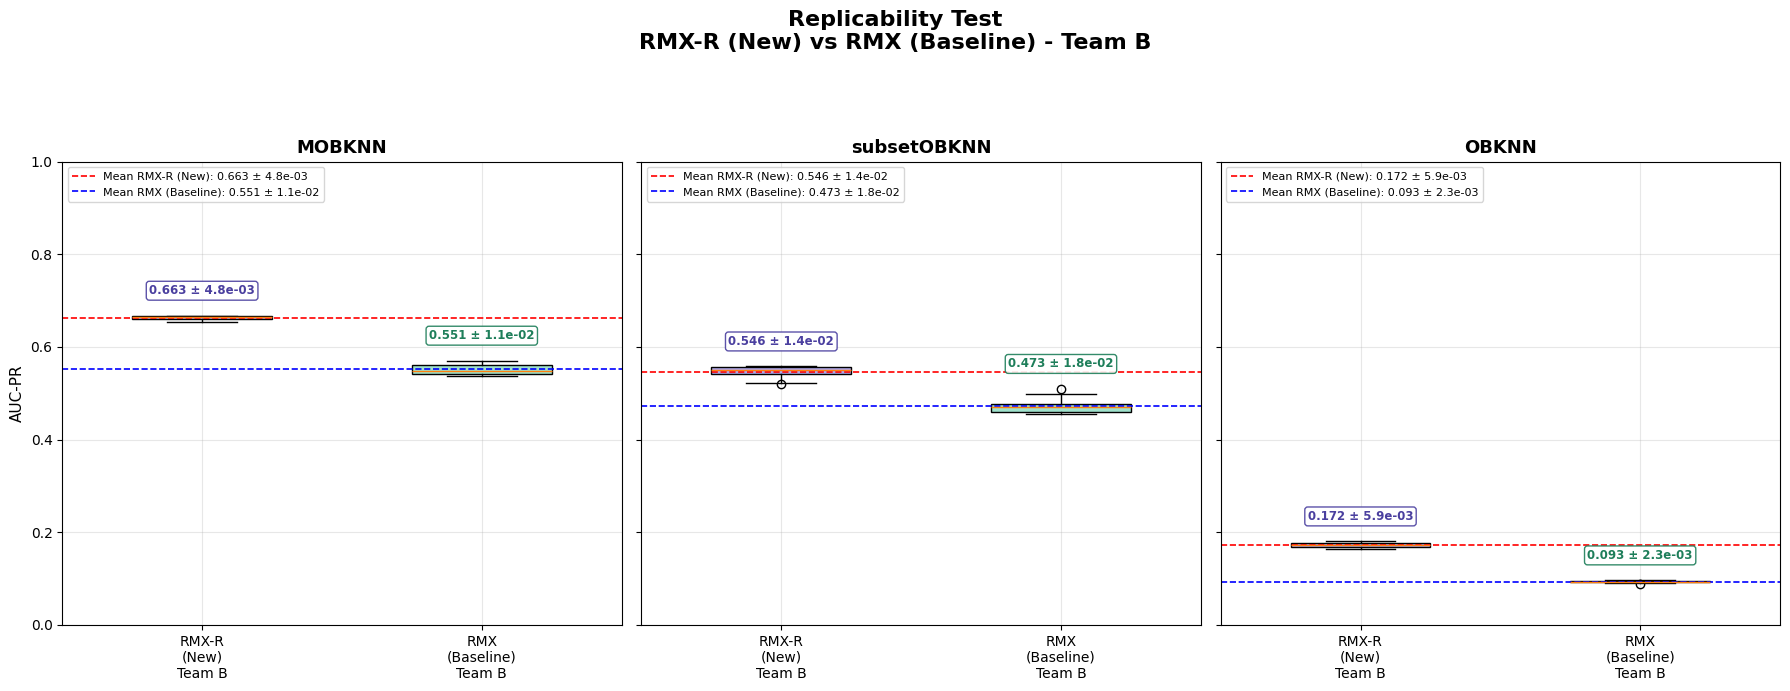

Method,RMX-R (New) - Team B,RMX (Baseline) - Team B
MOBKNN,0.663 ± 4.8e-03,0.551 ± 1.1e-02
subsetOBKNN,0.546 ± 1.4e-02,0.473 ± 1.8e-02
OBKNN,0.172 ± 5.9e-03,0.093 ± 2.3e-03


\begin{table}[!htbp]
\centering
\caption{Replicability Test (Team B): Mean AUC-PR $\pm$ standard deviation across RMX-R (New) and RMX (Baseline) datasets. The highest value is highlighted in bold, and the second best is underlined.}
\label{tab:auc_pr_replicability_team_b}
\footnotesize
\setlength{\tabcolsep}{8pt}
\begin{tabular}{lcc}
\toprule
\textbf{Method} & \textbf{RMX-R (New) - Team B} & \textbf{RMX (Baseline) - Team B} \\
\midrule
MOBKNN & \textbf{0.663} $\pm$ 4.8e-03 & \textbf{0.551} $\pm$ 1.1e-02 \\ \addlinespace
subsetOBKNN & \underline{0.546} $\pm$ 1.4e-02 & \underline{0.473} $\pm$ 1.8e-02 \\ \addlinespace
OBKNN & 0.172 $\pm$ 5.9e-03 & 0.093 $\pm$ 2.3e-03 \\
\bottomrule
\end{tabular}
\end{table}


In [31]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# Directories
# ==========================================================
BASE_DIR = Path.cwd() if (Path.cwd() / "Robustness (Team B)").exists() else Path(r"C:\Users\nicol\Plots + Data")
ROBUSTNESS_DIR = BASE_DIR / "Robustness (Team B)"

# ==========================================================
# Replicability Test (RMX-R vs RMX)
# Team B
# ==========================================================

datasets = {
    "MOBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMXR_MOBKNN.csv"),
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_MOBKNN.csv")
    ),
    "subsetOBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMXR_subsetOBKNN.csv"),
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_subsetOBKNN.csv")
    ),
    "OBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMXR_OBKNN.csv"),
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_OBKNN.csv")
    )
}

# ==========================================================
# Figure : 1 ligne × 3 colonnes
# ==========================================================
fig, axes = plt.subplots(
    1,
    len(datasets),
    figsize=(18, 7),
    sharey=True
)

for i, (ax, (name, (df, baseline_df))) in enumerate(zip(axes, datasets.items())):

    bp = ax.boxplot(
        [df["raw_pr_auc"], baseline_df["raw_pr_auc"]],
        tick_labels=[
            "RMX-R\n(New)\nTeam B",
            "RMX\n(Baseline)\nTeam B"
        ],
        patch_artist=True,
        widths=0.5
    )

    # Colors
    bp["boxes"][0].set_facecolor("#AFA9EC")
    bp["boxes"][1].set_facecolor("#9FE1CB")

    # Style
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)

    # Shared y-axis
    if i == 0:
        ax.set_ylabel("AUC-PR", fontsize=11)

    ax.set_title(
        name,
        fontsize=13,
        fontweight="bold"
    )

    mean_new, std_new = df["raw_pr_auc"].mean(), df["raw_pr_auc"].std()
    mean_baseline, std_baseline = baseline_df["raw_pr_auc"].mean(), baseline_df["raw_pr_auc"].std()

    ax.axhline(
        mean_new,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean RMX-R (New): {mean_new:.3f} ± {std_new:.1e}"
    )

    ax.axhline(
        mean_baseline,
        color="blue",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean RMX (Baseline): {mean_baseline:.3f} ± {std_baseline:.1e}"
    )

    # Annotate value ± std directly above each boxplot
    for x_pos, series, m_val, s_val, color in [
        (1, df["raw_pr_auc"], mean_new, std_new, "#4A3F9F"),
        (2, baseline_df["raw_pr_auc"], mean_baseline, std_baseline, "#1E7E5A")
    ]:
        ax.text(
            x_pos,
            min(series.max() + 0.04, 0.94),
            f"{m_val:.3f} ± {s_val:.1e}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color=color,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9)
        )

    ax.legend(
        loc="upper left",
        fontsize=8,
        frameon=True
    )

plt.suptitle(
    "Replicability Test\nRMX-R (New) vs RMX (Baseline) - Team B",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.show()

# ==========================================================
# Publication Table (HTML + LaTeX) : Replicability Test - Team B
# ==========================================================
latex_replicability_B = render_and_build_table(
    datasets,
    "RMX-R (New) - Team B",
    "RMX (Baseline) - Team B",
    "Replicability Test (Team B): Mean AUC-PR $\\pm$ standard deviation across RMX-R (New) and RMX (Baseline) datasets. The highest value is highlighted in bold, and the second best is underlined.",
    "tab:auc_pr_replicability_team_b"
)
print(latex_replicability_B)

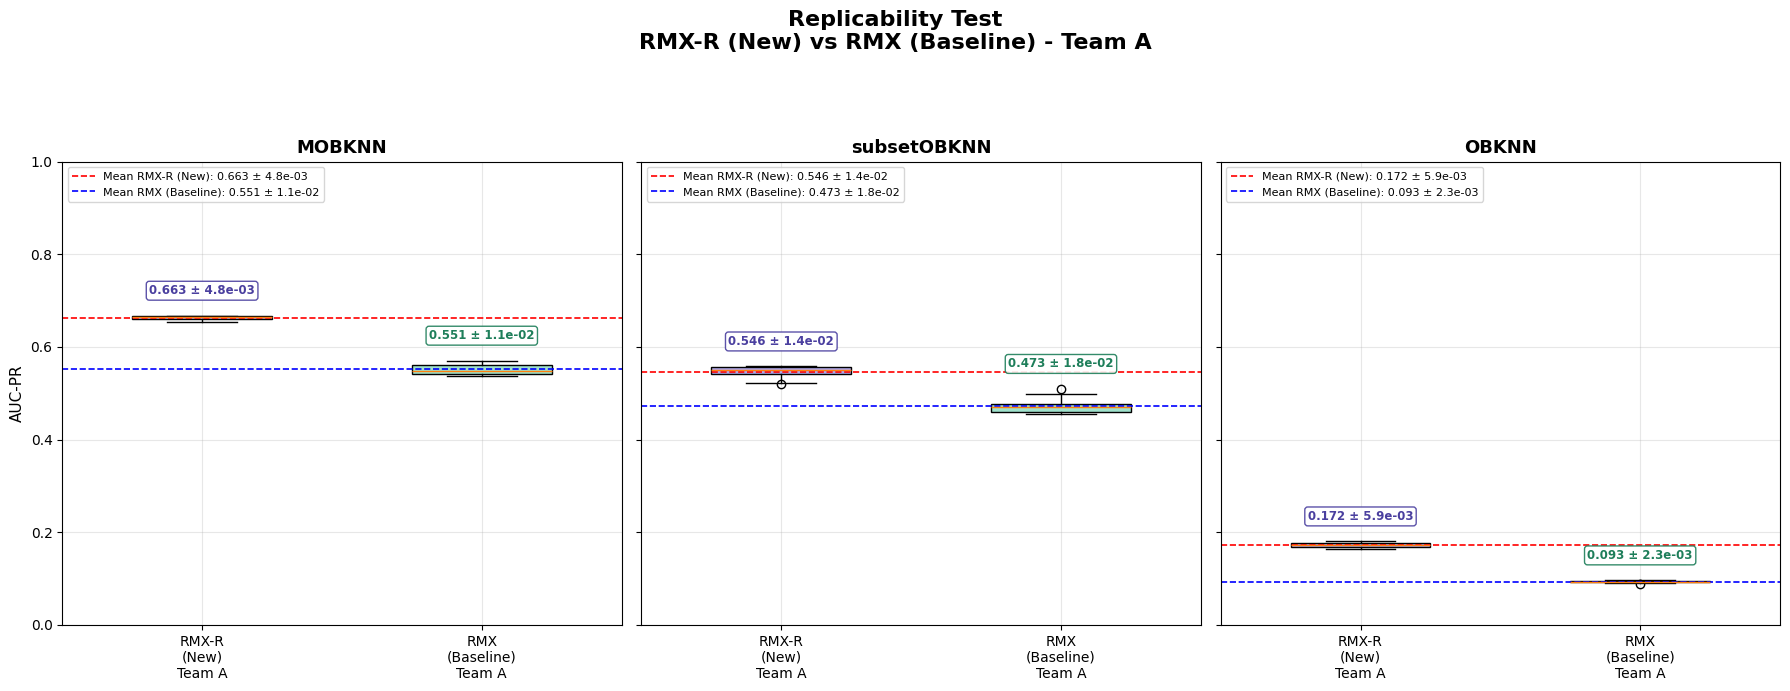

Method,RMX-R (New) - Team A,RMX (Baseline) - Team A
MOBKNN,0.663 ± 4.8e-03,0.551 ± 1.1e-02
subsetOBKNN,0.546 ± 1.4e-02,0.473 ± 1.8e-02
OBKNN,0.172 ± 5.9e-03,0.093 ± 2.3e-03


\begin{table}[!htbp]
\centering
\caption{Replicability Test (Team A): Mean AUC-PR $\pm$ standard deviation across RMX-R (New) and RMX (Baseline) datasets. The highest value is highlighted in bold, and the second best is underlined.}
\label{tab:auc_pr_replicability_team_a}
\footnotesize
\setlength{\tabcolsep}{8pt}
\begin{tabular}{lcc}
\toprule
\textbf{Method} & \textbf{RMX-R (New) - Team A} & \textbf{RMX (Baseline) - Team A} \\
\midrule
MOBKNN & \textbf{0.663} $\pm$ 4.8e-03 & \textbf{0.551} $\pm$ 1.1e-02 \\ \addlinespace
subsetOBKNN & \underline{0.546} $\pm$ 1.4e-02 & \underline{0.473} $\pm$ 1.8e-02 \\ \addlinespace
OBKNN & 0.172 $\pm$ 5.9e-03 & 0.093 $\pm$ 2.3e-03 \\
\bottomrule
\end{tabular}
\end{table}


In [32]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# Directories
# ==========================================================
BASE_DIR = Path.cwd() if (Path.cwd() / "Baseline (Team A)").exists() else Path(r"C:\Users\nicol\Plots + Data")
BASELINE_DIR = BASE_DIR / "Baseline (Team A)"

# ==========================================================
# Replicability Test (RMX-R vs RMX)
# Team A
# ==========================================================

datasets = {
    "MOBKNN": (
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMXR_MOBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_MOBKNN.csv")
    ),
    "subsetOBKNN": (
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMXR_subsetobknn.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_subsetobknn.csv")
    ),
    "OBKNN": (
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMXR_OBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_OBKNN.csv")
    )
}

# ==========================================================
# Figure : 1 ligne × 3 colonnes
# ==========================================================
fig, axes = plt.subplots(
    1,
    len(datasets),
    figsize=(18, 7),
    sharey=True
)

for i, (ax, (name, (df, baseline_df))) in enumerate(zip(axes, datasets.items())):

    bp = ax.boxplot(
        [df["raw_pr_auc"], baseline_df["raw_pr_auc"]],
        tick_labels=[
            "RMX-R\n(New)\nTeam A",
            "RMX\n(Baseline)\nTeam A"
        ],
        patch_artist=True,
        widths=0.5
    )

    # Colors
    bp["boxes"][0].set_facecolor("#AFA9EC")
    bp["boxes"][1].set_facecolor("#9FE1CB")

    # Style
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)

    # Shared y-axis
    if i == 0:
        ax.set_ylabel("AUC-PR", fontsize=11)

    ax.set_title(
        name,
        fontsize=13,
        fontweight="bold"
    )

    mean_new, std_new = df["raw_pr_auc"].mean(), df["raw_pr_auc"].std()
    mean_baseline, std_baseline = baseline_df["raw_pr_auc"].mean(), baseline_df["raw_pr_auc"].std()

    ax.axhline(
        mean_new,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean RMX-R (New): {mean_new:.3f} ± {std_new:.1e}"
    )

    ax.axhline(
        mean_baseline,
        color="blue",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean RMX (Baseline): {mean_baseline:.3f} ± {std_baseline:.1e}"
    )

    # Annotate value ± std directly above each boxplot
    for x_pos, series, m_val, s_val, color in [
        (1, df["raw_pr_auc"], mean_new, std_new, "#4A3F9F"),
        (2, baseline_df["raw_pr_auc"], mean_baseline, std_baseline, "#1E7E5A")
    ]:
        ax.text(
            x_pos,
            min(series.max() + 0.04, 0.94),
            f"{m_val:.3f} ± {s_val:.1e}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color=color,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9)
        )

    ax.legend(
        loc="upper left",
        fontsize=8,
        frameon=True
    )

plt.suptitle(
    "Replicability Test\nRMX-R (New) vs RMX (Baseline) - Team A",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.show()

# ==========================================================
# Publication Table (HTML + LaTeX) : Replicability Test - Team A
# ==========================================================
latex_replicability_A = render_and_build_table(
    datasets,
    "RMX-R (New) - Team A",
    "RMX (Baseline) - Team A",
    "Replicability Test (Team A): Mean AUC-PR $\\pm$ standard deviation across RMX-R (New) and RMX (Baseline) datasets. The highest value is highlighted in bold, and the second best is underlined.",
    "tab:auc_pr_replicability_team_a"
)
print(latex_replicability_A)

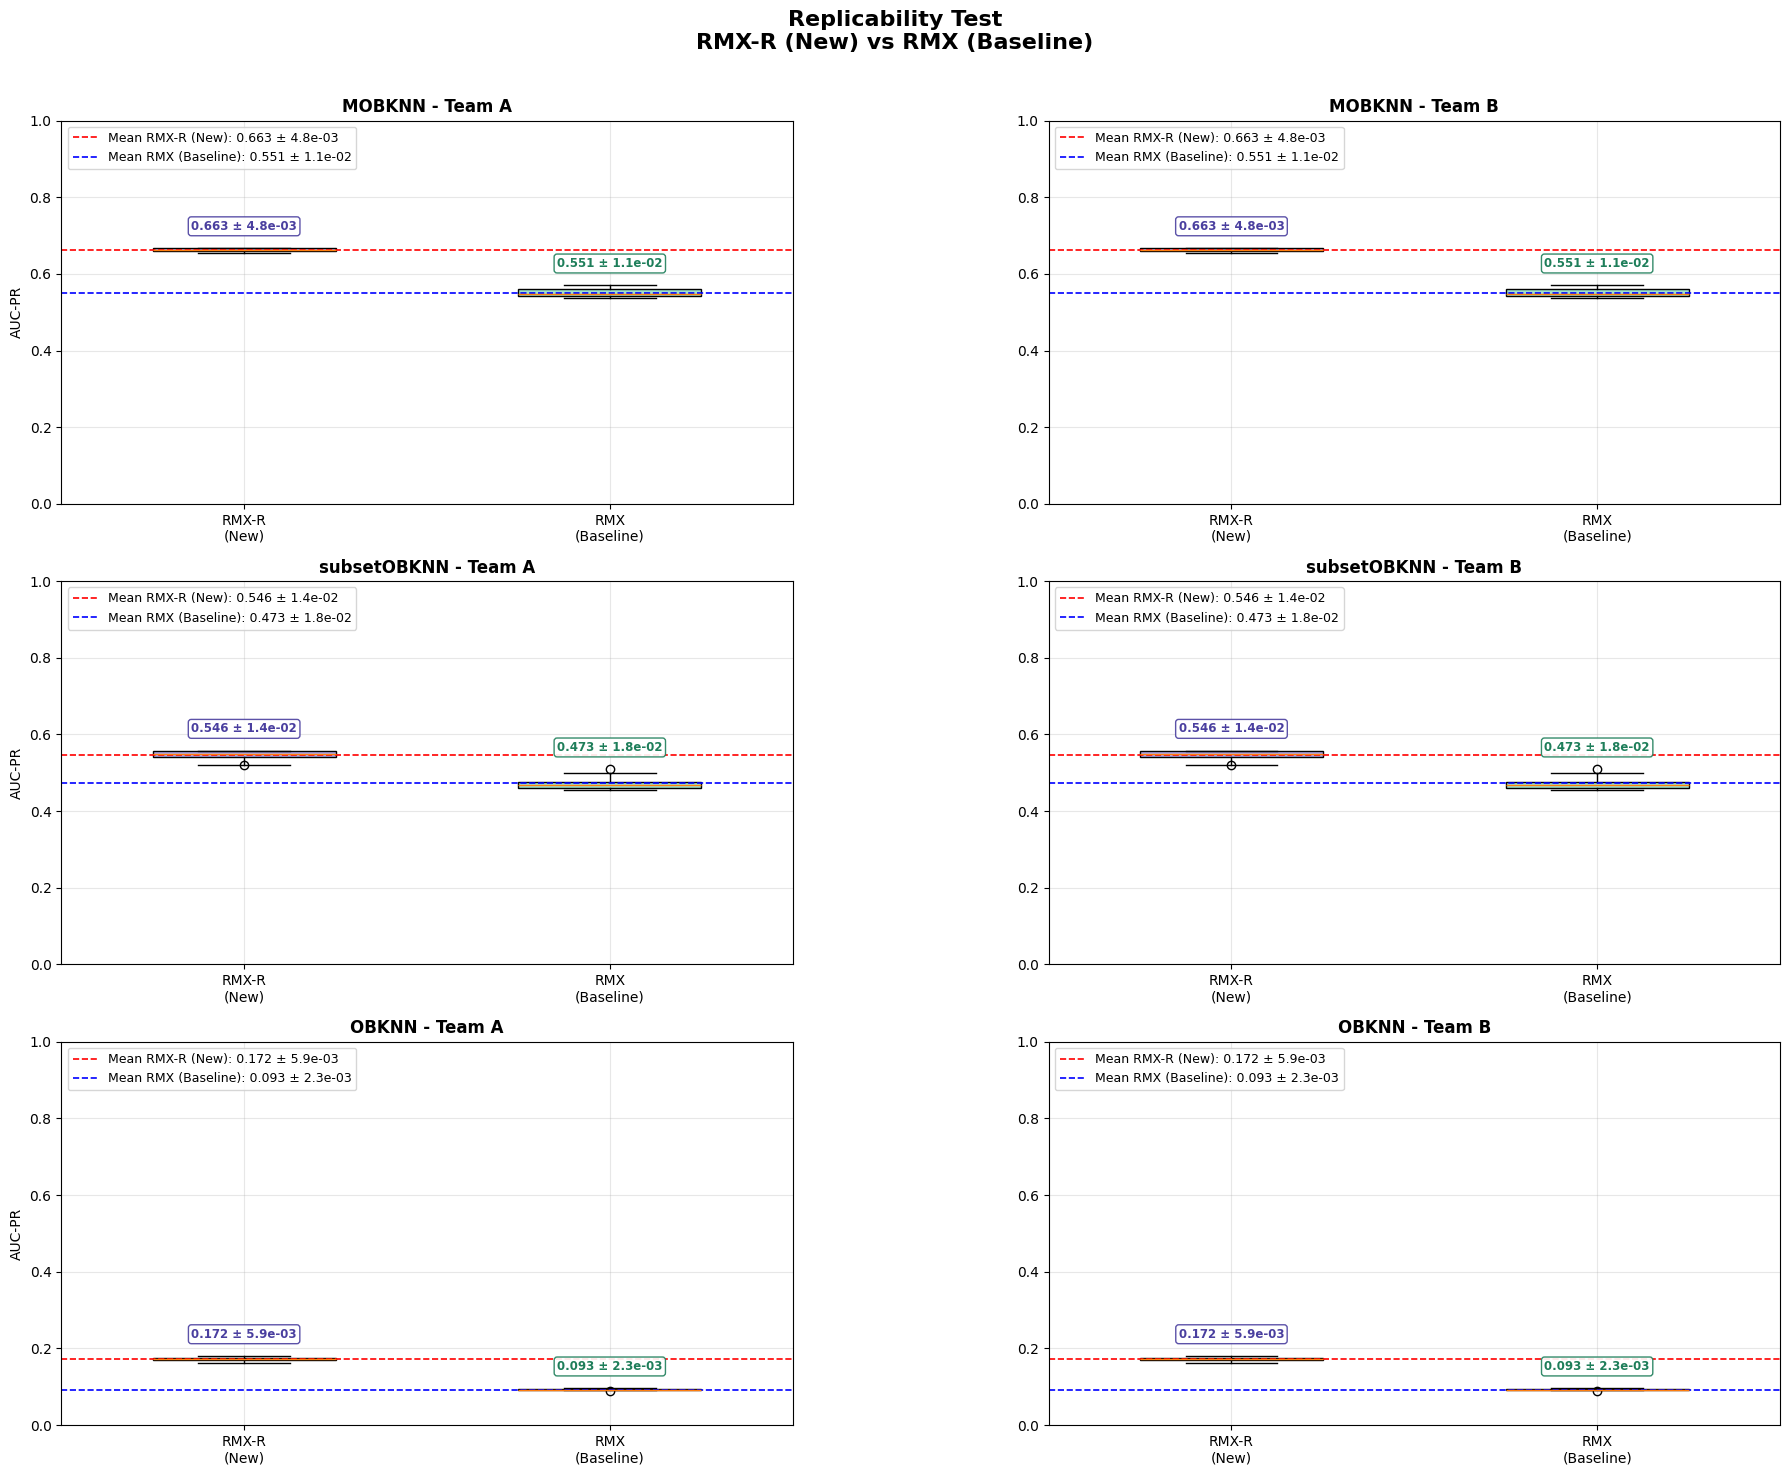

Method,Team A Baseline(RMX),Team A Repeatability(RMX New),Team B Reproducibility(RMX New),Team A Replicability(RMX-R New),Team B Replicability(RMX-R New)
MOBKNN,0.551 ± 1.1e-02,0.551 ± 1.1e-02,0.551 ± 1.1e-02,0.663 ± 4.8e-03,0.663 ± 4.8e-03
subsetOBKNN,0.473 ± 1.8e-02,0.473 ± 1.8e-02,0.473 ± 1.8e-02,0.546 ± 1.4e-02,0.546 ± 1.4e-02
OBKNN,0.093 ± 2.3e-03,0.093 ± 2.3e-03,0.093 ± 2.3e-03,0.172 ± 5.9e-03,0.172 ± 5.9e-03


\begin{table}[!htbp]
\centering
\caption{Mean AUC-PR $\pm$ standard deviation across all robustness evaluation scenarios (Repeatability, Reproducibility, and Replicability on RMX and RMX-R). The highest value is highlighted in bold, and the second best is underlined.}
\label{tab:auc_pr_robustness_all}
\footnotesize
\setlength{\tabcolsep}{6pt}
\begin{tabular}{lccccc}
\toprule
\textbf{Method} & \textbf{Team A Base (RMX)} & \textbf{Team A Rep. (RMX)} & \textbf{Team B Reprod. (RMX)} & \textbf{Team A Repl. (RMX-R)} & \textbf{Team B Repl. (RMX-R)} \\
\midrule
MOBKNN & \textbf{0.551} $\pm$ 1.1e-02 & \textbf{0.551} $\pm$ 1.1e-02 & \textbf{0.551} $\pm$ 1.1e-02 & \textbf{0.663} $\pm$ 4.8e-03 & \textbf{0.663} $\pm$ 4.8e-03 \\ \addlinespace
subsetOBKNN & \underline{0.473} $\pm$ 1.8e-02 & \underline{0.473} $\pm$ 1.8e-02 & \underline{0.473} $\pm$ 1.8e-02 & \underline{0.546} $\pm$ 1.4e-02 & \underline{0.546} $\pm$ 1.4e-02 \\ \addlinespace
OBKNN & 0.093 $\pm$ 2.3e-03 & 0.093 $\pm$ 2.3e-03 & 0.093 $\pm

In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# Directories
# ==========================================================
BASE_DIR = Path.cwd() if (Path.cwd() / "Baseline (Team A)").exists() else Path(r"C:\Users\nicol\Plots + Data")
BASELINE_DIR = BASE_DIR / "Baseline (Team A)"
ROBUSTNESS_DIR = BASE_DIR / "Robustness (Team B)"

# ==========================================================
# Team A (Baseline)
# ==========================================================
datasets_A = {
    "MOBKNN": (
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMXR_MOBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_MOBKNN.csv")
    ),
    "subsetOBKNN": (
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMXR_subsetobknn.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_subsetobknn.csv")
    ),
    "OBKNN": (
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMXR_OBKNN.csv"),
        pd.read_csv(BASELINE_DIR / "summary_results_baseline_RMX_OBKNN.csv")
    )
}

# ==========================================================
# Team B (Robustness)
# ==========================================================
datasets_B = {
    "MOBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMXR_MOBKNN.csv"),
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_MOBKNN.csv")
    ),
    "subsetOBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMXR_subsetOBKNN.csv"),
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_subsetOBKNN.csv")
    ),
    "OBKNN": (
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMXR_OBKNN.csv"),
        pd.read_csv(ROBUSTNESS_DIR / "summary_results_RMX_OBKNN.csv")
    )
}

# ==========================================================
# Figure : 3 lignes × (Team A | espace | Team B)
# ==========================================================
fig = plt.figure(figsize=(18, 15))

gs = fig.add_gridspec(
    3, 3,
    width_ratios=[1, 0.35, 1],
    wspace=0.0
)

axes = np.empty((3, 2), dtype=object)

for i in range(3):
    axes[i, 0] = fig.add_subplot(gs[i, 0])
    axes[i, 1] = fig.add_subplot(gs[i, 2], sharey=axes[0, 0] if i > 0 else None)

# ==========================================================
# Plot
# ==========================================================
for i, name in enumerate(datasets_A.keys()):

    # -----------------------
    # Team A
    # -----------------------
    ax = axes[i, 0]
    df, baseline_df = datasets_A[name]

    bp = ax.boxplot(
        [df["raw_pr_auc"], baseline_df["raw_pr_auc"]],
        tick_labels=["RMX-R\n(New)", "RMX\n(Baseline)"],
        patch_artist=True,
        widths=0.5
    )

    bp["boxes"][0].set_facecolor("#AFA9EC")
    bp["boxes"][1].set_facecolor("#9FE1CB")

    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)
    ax.set_ylabel("AUC-PR")
    ax.set_title(f"{name} - Team A", fontsize=12, fontweight="bold")

    mean_rmxr, std_rmxr = df["raw_pr_auc"].mean(), df["raw_pr_auc"].std()
    mean_rmx, std_rmx = baseline_df["raw_pr_auc"].mean(), baseline_df["raw_pr_auc"].std()

    ax.axhline(
        mean_rmxr,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean RMX-R (New): {mean_rmxr:.3f} ± {std_rmxr:.1e}"
    )

    ax.axhline(
        mean_rmx,
        color="blue",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean RMX (Baseline): {mean_rmx:.3f} ± {std_rmx:.1e}"
    )

    for x_pos, series, m_val, s_val, color in [
        (1, df["raw_pr_auc"], mean_rmxr, std_rmxr, "#4A3F9F"),
        (2, baseline_df["raw_pr_auc"], mean_rmx, std_rmx, "#1E7E5A")
    ]:
        ax.text(
            x_pos,
            min(series.max() + 0.04, 0.94),
            f"{m_val:.3f} ± {s_val:.1e}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color=color,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9)
        )

    ax.legend(loc="upper left", fontsize=9)

    # -----------------------
    # Team B
    # -----------------------
    ax = axes[i, 1]
    df, baseline_df = datasets_B[name]

    bp = ax.boxplot(
        [df["raw_pr_auc"], baseline_df["raw_pr_auc"]],
        tick_labels=["RMX-R\n(New)", "RMX\n(Baseline)"],
        patch_artist=True,
        widths=0.5
    )

    bp["boxes"][0].set_facecolor("#AFA9EC")
    bp["boxes"][1].set_facecolor("#9FE1CB")

    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)
    ax.set_title(f"{name} - Team B", fontsize=12, fontweight="bold")

    mean_rmxr, std_rmxr = df["raw_pr_auc"].mean(), df["raw_pr_auc"].std()
    mean_rmx, std_rmx = baseline_df["raw_pr_auc"].mean(), baseline_df["raw_pr_auc"].std()

    ax.axhline(
        mean_rmxr,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean RMX-R (New): {mean_rmxr:.3f} ± {std_rmxr:.1e}"
    )

    ax.axhline(
        mean_rmx,
        color="blue",
        linestyle="--",
        linewidth=1.2,
        label=f"Mean RMX (Baseline): {mean_rmx:.3f} ± {std_rmx:.1e}"
    )

    for x_pos, series, m_val, s_val, color in [
        (1, df["raw_pr_auc"], mean_rmxr, std_rmxr, "#4A3F9F"),
        (2, baseline_df["raw_pr_auc"], mean_rmx, std_rmx, "#1E7E5A")
    ]:
        ax.text(
            x_pos,
            min(series.max() + 0.04, 0.94),
            f"{m_val:.3f} ± {s_val:.1e}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
            color=color,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9)
        )

    ax.legend(loc="upper left", fontsize=9)

# ==========================================================
# Global title
# ==========================================================
fig.suptitle(
    "Replicability Test\nRMX-R (New) vs RMX (Baseline)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# ==========================================================
# Publication Table (HTML + LaTeX) : Combined Replicability & All Tests
# ==========================================================
from IPython.display import display, HTML

REPEATABILITY_DIR = BASE_DIR / "Repeatability (Team A)"
rep_A = {
    "MOBKNN": pd.read_csv(REPEATABILITY_DIR / "summary_results_repetabiliy_RMX_MOBKNN.csv")["raw_pr_auc"],
    "subsetOBKNN": pd.read_csv(REPEATABILITY_DIR / "summary_results_repetabiliy_RMX_subsetobknn.csv")["raw_pr_auc"],
    "OBKNN": pd.read_csv(REPEATABILITY_DIR / "summary_results_repetabiliy_RMX_OBKNN.csv")["raw_pr_auc"]
}

stats_comb = {}
for method in datasets_A.keys():
    a_rmxr, a_rmx = datasets_A[method][0]["raw_pr_auc"], datasets_A[method][1]["raw_pr_auc"]
    b_rmxr, b_rmx = datasets_B[method][0]["raw_pr_auc"], datasets_B[method][1]["raw_pr_auc"]
    a_rep = rep_A[method]
    stats_comb[method] = {
        "a_rmx": (a_rmx.mean(), a_rmx.std()),
        "a_rep": (a_rep.mean(), a_rep.std()),
        "b_rmx": (b_rmx.mean(), b_rmx.std()),
        "a_rmxr": (a_rmxr.mean(), a_rmxr.std()),
        "b_rmxr": (b_rmxr.mean(), b_rmxr.std())
    }

col_keys = ["a_rmx", "a_rep", "b_rmx", "a_rmxr", "b_rmxr"]
ranks_comb = {}
for col_key in col_keys:
    ordered = sorted(stats_comb.keys(), key=lambda m: stats_comb[m][col_key][0], reverse=True)
    ranks_comb[col_key] = {ordered[0]: 1, ordered[1]: 2}

def fmt_comb_latex(method, col_key):
    m_val, s_val = stats_comb[method][col_key]
    m_str = f"{m_val:.3f}"
    if ranks_comb[col_key].get(method) == 1:
        m_str = f"\\textbf{{{m_str}}}"
    elif ranks_comb[col_key].get(method) == 2:
        m_str = f"\\underline{{{m_str}}}"
    return f"{m_str} $\\pm$ {s_val:.1e}"

def fmt_comb_html(method, col_key):
    m_val, s_val = stats_comb[method][col_key]
    m_str = f"{m_val:.3f}"
    if ranks_comb[col_key].get(method) == 1:
        m_str = f"<b>{m_str}</b>"
    elif ranks_comb[col_key].get(method) == 2:
        m_str = f"<u>{m_str}</u>"
    return f"{m_str} &plusmn; {s_val:.1e}"

methods_comb = list(datasets_A.keys())
html_rows_comb = "".join([
    f"<tr><td style='text-align:left;padding:6px 10px;'>{m}</td>" +
    "".join([f"<td style='text-align:center;padding:6px 10px;'>{fmt_comb_html(m, k)}</td>" for k in col_keys]) +
    "</tr>"
    for m in methods_comb
])

display(HTML(f"""
<div style='margin:12px 0;font-family:serif;'>
  <p style='margin-bottom:6px;font-size:13px;'><b>Master Table (tab:auc_pr_robustness_all):</b> Mean AUC-PR &plusmn; standard deviation across all Robustness tests (Baseline, Repeatability, Reproducibility, and Replicability). The highest value is highlighted in bold, and the second best is underlined.</p>
  <table style='border-collapse:collapse;border-top:2px solid black;border-bottom:2px solid black;font-size:12.5px;'>
    <thead>
      <tr style='border-bottom:1px solid black;'>
        <th style='text-align:left;padding:6px 10px;'>Method</th>
        <th style='text-align:center;padding:6px 10px;'>Team A Baseline<br>(RMX)</th>
        <th style='text-align:center;padding:6px 10px;'>Team A Repeatability<br>(RMX New)</th>
        <th style='text-align:center;padding:6px 10px;'>Team B Reproducibility<br>(RMX New)</th>
        <th style='text-align:center;padding:6px 10px;'>Team A Replicability<br>(RMX-R New)</th>
        <th style='text-align:center;padding:6px 10px;'>Team B Replicability<br>(RMX-R New)</th>
      </tr>
    </thead>
    <tbody>{html_rows_comb}</tbody>
  </table>
</div>
"""))

lines_comb = [
    "\\begin{table}[!htbp]",
    "\\centering",
    "\\caption{Mean AUC-PR $\\pm$ standard deviation across all robustness evaluation scenarios (Repeatability, Reproducibility, and Replicability on RMX and RMX-R). The highest value is highlighted in bold, and the second best is underlined.}",
    "\\label{tab:auc_pr_robustness_all}",
    "\\footnotesize",
    "\\setlength{\\tabcolsep}{6pt}",
    "\\begin{tabular}{lccccc}",
    "\\toprule",
    "\\textbf{Method} & \\textbf{Team A Base (RMX)} & \\textbf{Team A Rep. (RMX)} & \\textbf{Team B Reprod. (RMX)} & \\textbf{Team A Repl. (RMX-R)} & \\textbf{Team B Repl. (RMX-R)} \\\\",
    "\\midrule"
]
for idx, m in enumerate(methods_comb):
    end = " \\\\ \\addlinespace" if idx < len(methods_comb) - 1 else " \\\\"
    row_str = " & ".join([m] + [fmt_comb_latex(m, k) for k in col_keys])
    lines_comb.append(row_str + end)
lines_comb += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
print("\n".join(lines_comb))